# July 2021 floods — case notebook (v2), team 9

**Our answer:** Warn before the water, shelter where people have none.

**Anna's question:** after everything done since 2021, would the border area around Liege, Belgian and Dutch Limburg and the Aachen region be better prepared if that flood returned tomorrow? A warning bulletin is already active (heavy rain forecast on the Meuse and Vesdre within days).

# July 2021 floods: starter notebook

This notebook does two things:
1. **Connects** you to the challenge data in the cloud. Nothing is downloaded, and no login is needed: the data is public.
2. **Shows what data is available** (EMS flood maps, EFAS flood hazard, GHS-OBAT buildings, GHS-POP population for DE, BE, NL).

Click **Run all**. Works in Colab and on a laptop.

<details>
<summary><b>Not using Colab? (VS Code, Jupyter, any Python)</b></summary>

1. `pip install gcsfs pyogrio rasterio geopandas shapely ipykernel`
   (on Windows, if that fails: `conda install -c conda-forge geopandas rasterio pyogrio gcsfs`)
2. VS Code: install the Python and Jupyter extensions and pick your environment as kernel. If the packages are already installed there, you can skip the `pip install` cell below. After installing, restart the kernel.

**Problems:** *connection or timeout errors* → check your internet connection and retry · *`No such file` on a path* → run the Explore cell to see the exact file names · *`ModuleNotFoundError`* → the kernel and your terminal use different Pythons: install with `%pip install gcsfs` inside the notebook, then restart the kernel.

</details>

## 1. Setup

In [1]:
%%capture
%pip install -q gcsfs pyogrio rasterio geopandas shapely

In [2]:
import os, re, warnings
from pathlib import Path
import pandas as pd
warnings.filterwarnings("ignore")

BUCKET = "datasets_challenge"
FOLDER = "working_data"

## 2. Connect

In [3]:
import gcsfs

# The bucket is public: no login needed.
os.environ["GS_NO_SIGN_REQUEST"] = "YES"      # lets GDAL (rasterio, pyogrio) read it anonymously
GDAL_PREFIX = "/vsigs/"
ROOT = f"{BUCKET}/{FOLDER}"
fs = gcsfs.GCSFileSystem(token="anon")
print("Connected:", [Path(p).name for p in fs.ls(ROOT)])

Connected: ['cems-efas', 'ems_be', 'ems_de', 'ems_nl', 'ghs_pop', 'obat_be', 'obat_de', 'obat_nl']


## 3. Explore

In [4]:
for folder in ["cems-efas", "ghs_pop", "obat_be", "obat_de", "obat_nl", "ems_be", "ems_de", "ems_nl"]:
    print(f"\n{folder}")
    files = fs.find(f"{ROOT}/{folder}", detail=True)
    if folder.startswith("ems_"):
        # vector products: one line per product directory
        dirs = {}
        for p, info in sorted(files.items()):
            d = dirs.setdefault(Path(p).parent.name, [0, 0])
            d[0] += p.lower().endswith(".shp"); d[1] += int(info["size"])
        for name, (n_shp, size) in dirs.items(): print("  ", name, f"{n_shp} shp, {size/1e6:,.1f} MB")
    else:
        for p, info in sorted(files.items()):
            if p.lower().endswith((".tif", ".tiff", ".gpkg")): print("  ", Path(p).name, f"{int(info['size'])/1e6:,.0f} MB")

# EMS: one row per area (aoi), type (DEL/GRA) and version, with its layers
EMS_RE = re.compile(r"(EMSR\d+)_(AOI\d+)_([A-Z]+)_(PRODUCT|MONIT\d*)_(\w+?)_r\d+_v\d+", re.I)
rows = []
for cc in ("de", "be", "nl"):
    for p in fs.find(f"{ROOT}/ems_{cc}"):
        m = EMS_RE.search(Path(p).name) if p.lower().endswith(".shp") else None
        if m: rows.append(dict(cc=cc, aoi=m[2], ptype=m[3].upper(), ver=m[4].upper(), layer=m[5]))
display(pd.DataFrame(rows).groupby(["cc", "aoi", "ptype", "ver"]).layer.apply(lambda s: ", ".join(sorted(s))).to_frame())


cems-efas
   Europe_RP100_filled_depth.tif 323 MB
   Europe_RP10_filled_depth.tif 272 MB
   Europe_RP500_filled_depth.tif 350 MB

ghs_pop
   GHS_POP_E2020_GLOBE_R2023A_4326_30ss_V1_0.tif 383 MB
   GHS_POP_E2025_GLOBE_R2023A_4326_30ss_V1_0.tif 384 MB

obat_be
   GHS_OBAT_GPKG_BEL_E2020_R2024A_V1_0.gpkg 1,433 MB

obat_de
   GHS_OBAT_GPKG_DEU_E2020_R2024A_V1_0.gpkg 8,579 MB

obat_nl
   GHS_OBAT_GPKG_NLD_E2020_R2024A_V1_0.gpkg 2,229 MB

ems_be
   EMSR518_AOI01_DEL_MONIT01_r1_VECTORS_v1_vector 9 shp, 65.4 MB
   EMSR518_AOI01_DEL_PRODUCT_r1_VECTORS_v1_vector 10 shp, 76.3 MB
   EMSR518_AOI02_DEL_MONIT01_r1_VECTORS_v1_vector 12 shp, 110.3 MB
   EMSR518_AOI02_DEL_PRODUCT_r1_VECTORS_v1_vector 10 shp, 138.3 MB

ems_de
   EMSR517_AOI01_DEL_MONIT01_r1_RTP01_v1_vector 11 shp, 21.3 MB
   EMSR517_AOI01_DEL_PRODUCT_r1_RTP01_v1_vector 10 shp, 21.3 MB
   EMSR517_AOI03_DEL_MONIT01_r1_RTP01_v1_vector 10 shp, 6.9 MB
   EMSR517_AOI03_DEL_PRODUCT_r1_RTP01_v1_vector 10 shp, 5.2 MB
   EMSR517_AOI04_DEL_MONIT01

layer
cc aoi   ptype ver                                                       
be AOI01 DEL   MONIT01  areaOfInterestA, builtUpA, facilitiesL, hydrog...
               PRODUCT  areaOfInterestA, builtUpA, facilitiesL, hydrog...
   AOI02 DEL   MONIT01  areaOfInterestA, builtUpA, facilitiesA, facili...
               PRODUCT  areaOfInterestA, facilitiesL, hydrographyA, hy...
de AOI01 DEL   MONIT01  areaOfInterestA, builtUpA, facilitiesA, facili...
               PRODUCT  areaOfInterestA, builtUpA, facilitiesL, hydrog...
   AOI03 DEL   MONIT01  areaOfInterestA, builtUpA, facilitiesA, facili...
               PRODUCT  areaOfInterestA, builtUpA, facilitiesA, facili...
   AOI04 DEL   MONIT01  areaOfInterestA, builtUpA, facilitiesA, facili...
               PRODUCT  areaOfInterestA, builtUpA, facilitiesL, hydrog...
   AOI05 DEL   MONIT01  areaOfInterestA, builtUpA, facilitiesL, hydrog...
               PRODUCT  areaOfInterestA, builtUpA, facilitiesL, hydrog...
   AOI06 DEL   MONIT01  areaOfInterestA, builtUpA, facilitiesL, hydrog...
               PRODUCT  areaOfInterestA, builtUpA, facilitiesL, hydrog...
   AOI07 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI08 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI09 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI10 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, facili...
   AOI11 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI14 GRA   PRODUCT  areaOfInterestA, builtUpP, hydrographyA, hydro...
   AOI15 GRA   MONIT01  areaOfInterestA, builtUpP, facilitiesA, hydrog...
               PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI16 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI17 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI18 GRA   PRODUCT  areaOfInterestA, builtUpP, facilitiesA, hydrog...
   AOI20 GRA   PRODUCT  areaOfInterestA, facilitiesA, hydrographyA, hy...
nl AOI01 DEL   PRODUCT  areaOfInterestA, builtUpA, facilitiesA, hydrog...

## 4. The case

One present-state assessment of the July 2021 floods, for the **cross-border area**: Liege (BE), Belgian Limburg, Dutch Limburg and the Aachen region (DE).
Decision-maker: **Anna, crisis coordinator**. Live trigger: an early-warning bulletin (heavy rain on the Meuse and Vesdre within days; ministers and mayors already calling).

| | Question (from the brief) | Where |
|---|---|---|
| Q1 | What did the 2021 floods cover? Map the extent, count people and buildings inside. | Section 5 |
| Q2 | What has been done since? Defences, rebuilding, shelter plans, critical sites, awareness. | Section 6 (`q2_sources.md`) |
| Q3 | Could we shelter them today? Safe buildings outside the flood zone, and who can reach one. | Section 7 |
| Q4 | Where are we still exposed? Name the areas, and the first action Anna should take. | Section 8 |

Products chosen for the border area (one EMS product per place). The Belgian Limburg has no EMS product in the bucket — a gap to state. The Vesdre (Verviers, Pepinster) is only in the EMSR518 AOI01 **MONIT01** pass.


In [5]:
TEAM = "team-9"                                   # from the organisers' desk

# Border area around Liege / Limburg / Aachen. Label each product for display.
PRODUCTS = [
    "EMSR518_AOI01_DEL_PRODUCT_v1",     # Liege / Chaudfontaine (BE, Vesdre-Meuse)
    "EMSR520_AOI01_DEL_PRODUCT_v1",     # Venlo–Roermond (NL, Dutch Limburg, Maas)
    "EMSR517_AOI09_GRA_PRODUCT_v1",     # Eschweiler (DE, Aachen region, Inde)
    # "EMSR518_AOI01_DEL_MONIT01_v1",   # uncomment: fuller BE extent incl. Verviers/Pepinster
]
# Named PLACE_LABELS, not LABELS, on purpose: the figure cell below builds a local
# list of class labels under the name LABELS. Sharing that name let the list shadow
# this product -> place dict and break the Q1/Q3/Q4 lookups (LABELS.get on a list).
# Distinct names make that collision impossible whatever order cells are run in.
PLACE_LABELS = {
    "EMSR518_AOI01_DEL_PRODUCT_v1": "Liege/Chaudfontaine (BE)",
    "EMSR520_AOI01_DEL_PRODUCT_v1": "Venlo–Roermond (NL)",
    "EMSR517_AOI09_GRA_PRODUCT_v1": "Eschweiler / Aachen region (DE)",
    "EMSR518_AOI01_DEL_MONIT01_v1": "Liege + Vesdre, later maps (BE)",
}
RETURN_PERIODS = [10, 100, 500]                   # the hazard maps in the bucket (cems-efas)

OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

## 5. Method: who did the water reach, and was it inside the flood map?

Copied from our pre-event code, so this notebook runs on its own (`event2021.py`, `event_2021.py`,
`validate.py`, `validate_2021.py`). How each number is measured:

- **Water seen:** EMS `observedEventA`, notations "Flooded area" and "Flood trace", cut to the
  product's area of interest. Outside that area nothing was mapped, so nothing is counted there.
- **Grid:** 20 m cells in EPSG:3035 (equal-area, so a cell count is an area), snapped to 100 m blocks.
  A polygon fills a cell when it covers the cell's centre.
- **Residents:** GHS-POP E2020 (30 arc-seconds, about 1 km). Each cell's count becomes a density per m²
  of its own ground area, put on the 20 m grid by nearest neighbour: a 1 km cell 30 % under water
  contributes 30 % of its residents (Annex 2), assuming they are spread evenly in the cell.
- **Flood map:** JRC hazard depth (`Europe_RP{rp}_filled_depth.tif`), nearest neighbour, wet when deeper
  than 0 m. No data counts as dry: the map does not model rivers below about 150 km² of catchment,
  and water there is a real miss.
- **Check:** the Ahr product `EMSR517_AOI15_GRA_PRODUCT_v1` must give **3,739 residents reached, 1,889
  (51 %) outside the 1-in-100-year map**, the brief's figure.

In [6]:
import numpy as np
import pyogrio, shapely, rasterio
import geopandas as gpd
from pyproj import Transformer
from rasterio.features import rasterize
from rasterio.transform import Affine
from rasterio.warp import Resampling, reproject, transform_bounds
from rasterio.windows import from_bounds

CRS, RES, BLOCK = "EPSG:3035", 20.0, 5
NOTATIONS = ("Flooded area", "Flood trace")
POP = f"{ROOT}/ghs_pop/GHS_POP_E2020_GLOBE_R2023A_4326_30ss_V1_0/GHS_POP_E2020_GLOBE_R2023A_4326_30ss_V1_0.tif"
HAZARD = f"{ROOT}/cems-efas/Europe_RP{{rp}}_filled_depth.tif"


def product_layer(product_id, layer):
    """GDAL path of one EMS layer of a product id such as EMSR517_AOI15_GRA_PRODUCT_v1."""
    stem, version = product_id.rsplit("_", 1)
    for folder in fs.glob(f"{ROOT}/ems_*/{stem}_r1_*_{version}_vector"):
        for path in fs.glob(f"{folder}/*_{layer}_r1_*.shp"):
            return GDAL_PREFIX + path
    raise FileNotFoundError(f"{product_id}: no {layer} layer (run the Explore cell for the exact ids)")


def union(geoms):
    """Polygonal union of geometries, or an empty polygon."""
    geoms = [g for g in geoms if g is not None and not g.is_empty]
    if not geoms:
        return shapely.Polygon()
    merged = shapely.union_all(shapely.make_valid(np.array(geoms, dtype=object)))
    parts = [g for g in shapely.get_parts(merged) if g.geom_type in ("Polygon", "MultiPolygon")]
    return shapely.union_all(parts) if parts else shapely.Polygon()


def grid_for(bounds_lonlat):
    """20 m EPSG:3035 grid over a lon/lat box, snapped outward to 100 m blocks: (transform, shape)."""
    left, bottom, right, top = transform_bounds("EPSG:4326", CRS, *bounds_lonlat, densify_pts=21)
    step = RES * BLOCK
    left, top = np.floor(left / step) * step, np.ceil(top / step) * step
    width = int(np.ceil((right - left) / step)) * BLOCK
    height = int(np.ceil((top - bottom) / step)) * BLOCK
    return Affine(RES, 0.0, left, 0.0, -RES, top), (height, width)


def mask_of(geom, transform, shape):
    """A lon/lat polygon as a boolean mask on the grid, by cell centre."""
    if geom.is_empty:
        return np.zeros(shape, dtype=bool)
    g = gpd.GeoSeries([geom], crs="EPSG:4326").to_crs(CRS).iloc[0]
    return rasterize([(g, 1)], out_shape=shape, transform=transform, fill=0, dtype="uint8").astype(bool)


def on_grid(path, transform, shape, src_window=None):
    """Band 1 of a bucket raster resampled onto the grid (nearest), nodata as NaN."""
    out = np.full(shape, np.nan, dtype="float32")
    with rasterio.open(path) as src:
        left, bottom, right, top = transform_bounds(CRS, src.crs, transform.c, transform.f + shape[0] * transform.e,
                                                    transform.c + shape[1] * transform.a, transform.f)
        win = from_bounds(left, bottom, right, top, src.transform).round_offsets().round_lengths()
        data = src.read(1, window=win, boundless=True, fill_value=src.nodata if src.nodata is not None else np.nan)
        reproject(source=data.astype("float32"), destination=out, src_transform=src.window_transform(win),
                  src_crs=src.crs, src_nodata=src.nodata, dst_transform=transform, dst_crs=CRS,
                  dst_nodata=np.nan, resampling=Resampling.nearest)
    return out


def residents_on_grid(transform, shape):
    """Residents per 20 m cell: GHS-POP density (per m2 of its own cell) times 400 m2."""
    left, bottom, right, top = transform_bounds(CRS, "EPSG:4326", transform.c, transform.f + shape[0] * transform.e,
                                                transform.c + shape[1] * transform.a, transform.f)
    pad = 0.02  # two 30" cells, so a cell on the edge is never cut
    with rasterio.open(GDAL_PREFIX + POP) as src:
        win = from_bounds(left - pad, bottom - pad, right + pad, top + pad, src.transform).round_offsets().round_lengths()
        counts = np.nan_to_num(src.read(1, window=win).astype("float64"), nan=0.0)
        pt = src.window_transform(win)
    counts[counts < 0] = 0.0
    # Ground area of each row of 30" cells, from its corners projected to equal-area EPSG:3035.
    to_laea = Transformer.from_crs("EPSG:4326", CRS, always_xy=True)
    tops = pt.f + np.arange(counts.shape[0]) * pt.e
    left_x, right_x = np.full_like(tops, pt.c), np.full_like(tops, pt.c + pt.a)
    xs = np.stack([left_x, right_x, right_x, left_x], axis=1)
    ys = np.stack([tops, tops, tops + pt.e, tops + pt.e], axis=1)
    px, py = to_laea.transform(xs, ys)
    row_area = 0.5 * np.abs(np.sum(px * np.roll(py, -1, axis=1) - np.roll(px, -1, axis=1) * py, axis=1))
    density = (counts / row_area[:, None]).astype("float32")
    out = np.zeros(shape, dtype="float32")
    reproject(source=density, destination=out, src_transform=pt, src_crs="EPSG:4326",
              dst_transform=transform, dst_crs=CRS, resampling=Resampling.nearest, dst_nodata=0.0)
    return out * np.float32(RES * RES)


def analyse(product_id, return_periods=RETURN_PERIODS):
    """One row per return period: residents the water reached, and how many lived outside the map."""
    aoi = union(pyogrio.read_dataframe(product_layer(product_id, "areaOfInterestA")).to_crs("EPSG:4326").geometry)
    events = pyogrio.read_dataframe(product_layer(product_id, "observedEventA")).to_crs("EPSG:4326")
    observed = union([union(events.loc[events["notation"].isin(NOTATIONS)].geometry).intersection(aoi)])
    transform, shape = grid_for(aoi.bounds)
    seen = mask_of(observed, transform, shape) & mask_of(aoi, transform, shape)
    people = residents_on_grid(transform, shape)
    reached = float(people[seen].sum())
    rows, wet_maps = [], {}
    for rp in return_periods:
        depth = on_grid(GDAL_PREFIX + HAZARD.format(rp=rp), transform, shape)
        wet = np.nan_to_num(depth, nan=0.0) > 0.0
        wet_maps[rp] = wet
        outside = float(people[seen & ~wet].sum())
        rows.append({"product_id": product_id, "return_period": rp,
                     "observed_km2": seen.sum() * RES * RES / 1e6,
                     "residents_reached": round(reached), "residents_outside_map": round(outside),
                     "share_outside_map": outside / reached if reached else np.nan})
    return pd.DataFrame(rows), {"transform": transform, "seen": seen, "wet": wet_maps,
                                "aoi": mask_of(aoi, transform, shape)}

### Q1: the numbers

One row per product and return period. `share_outside_map` is the share of the residents the water
reached who lived outside that flood map.

In [7]:
results, grids = [], {}
for pid in PRODUCTS:
    table, grids[pid] = analyse(pid)
    results.append(table)
q1_table = pd.concat(results, ignore_index=True)

q1_table["place"] = q1_table["product_id"].map(PLACE_LABELS)
display(q1_table.style.format({"observed_km2": "{:.2f}", "share_outside_map": "{:.0%}"}))

# Checks: reproduce the frozen on-scope figures before trusting any new number.
# (Values re-derived from the team's verified tables, event_2021_products.)
CHECKS = {
    "EMSR517_AOI09_GRA_PRODUCT_v1": (1213, 1107),   # Eschweiler: 91% outside RP100
    "EMSR518_AOI01_DEL_PRODUCT_v1": (1356, 175),    # Liege (first map): 13%
    "EMSR520_AOI01_DEL_PRODUCT_v1": (2449, 288),    # Venlo–Roermond: 12%
}
for pid, (reached, outside) in CHECKS.items():
    row = q1_table.query("product_id == @pid and return_period == 100")
    if len(row):
        r, o = row.residents_reached.iloc[0], row.residents_outside_map.iloc[0]
        assert abs(r - reached) <= 40 and abs(o - outside) <= 40, (pid, r, o)
        print(f"Check {PLACE_LABELS[pid]}: {int(r)} reached, {int(o)} outside the 1-in-100 map ({o/r:.0%}).")

# Method proof (handoff rule): the Ahr must still reproduce 3,739 / 1,889.
ahr, _ = analyse("EMSR517_AOI15_GRA_PRODUCT_v1")
a = ahr.query("return_period == 100").iloc[0]
assert abs(a.residents_reached - 3739) <= 40 and abs(a.residents_outside_map - 1889) <= 40, a
print("Method proof: Ahr gives", int(a.residents_reached), "reached,", int(a.residents_outside_map), "outside.")


,product_id,return_period,observed_km2,residents_reached,residents_outside_map,share_outside_map,place
0,EMSR518_AOI01_DEL_PRODUCT_v1,10,7.51,1356,277,20%,Liege/Chaudfontaine (BE)
1,EMSR518_AOI01_DEL_PRODUCT_v1,100,7.51,1356,175,13%,Liege/Chaudfontaine (BE)
2,EMSR518_AOI01_DEL_PRODUCT_v1,500,7.51,1356,172,13%,Liege/Chaudfontaine (BE)
3,EMSR520_AOI01_DEL_PRODUCT_v1,10,11.95,2449,425,17%,Venlo–Roermond (NL)
4,EMSR520_AOI01_DEL_PRODUCT_v1,100,11.95,2449,288,12%,Venlo–Roermond (NL)
5,EMSR520_AOI01_DEL_PRODUCT_v1,500,11.95,2449,238,10%,Venlo–Roermond (NL)
6,EMSR517_AOI09_GRA_PRODUCT_v1,10,3.19,1213,1111,92%,Eschweiler / Aachen region (DE)
7,EMSR517_AOI09_GRA_PRODUCT_v1,100,3.19,1213,1107,91%,Eschweiler / Aachen region (DE)
8,EMSR517_AOI09_GRA_PRODUCT_v1,500,3.19,1213,1102,91%,Eschweiler / Aachen region (DE)


Check Eschweiler / Aachen region (DE): 1213 reached, 1107 outside the 1-in-100 map (91%).
Check Liege/Chaudfontaine (BE): 1356 reached, 175 outside the 1-in-100 map (13%).
Check Venlo–Roermond (NL): 2449 reached, 288 outside the 1-in-100 map (12%).


Method proof: Ahr gives 3739 reached, 1889 outside.


### Figure: inside and outside the 1-in-100-year map

Same colours as the brief's Figure 1. Orange is small in area where it falls in town: it is people,
not area, that the share counts.

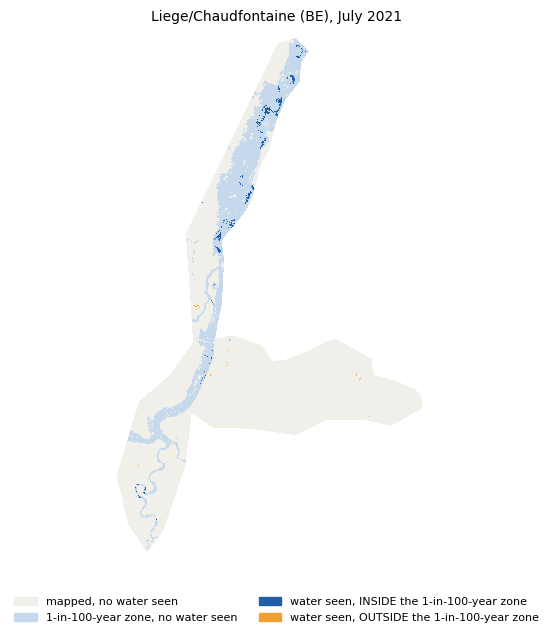

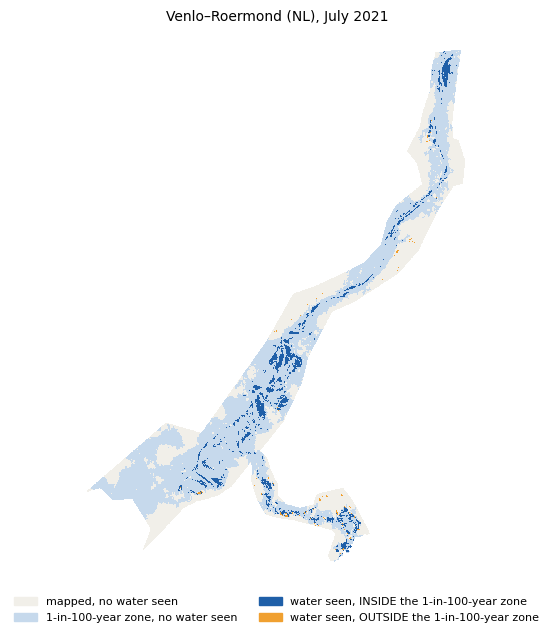

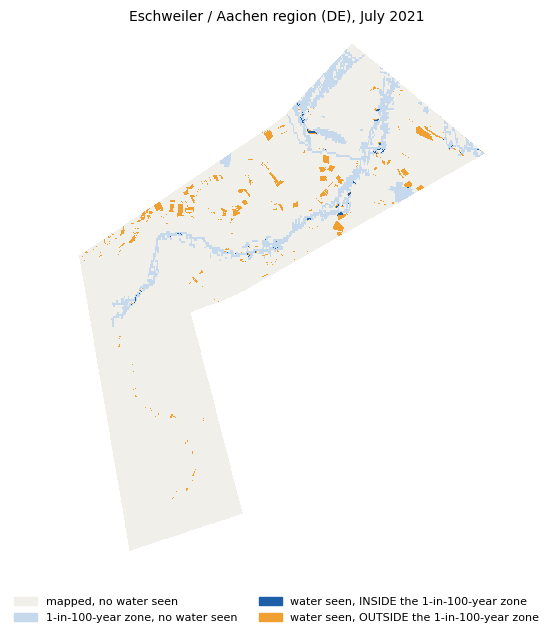

In [8]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

COLOURS = ["#f1efe9", "#c6d9ec", "#1f5fa8", "#f0a030"]   # mapped dry, map-only, water inside, water outside
LABELS = ["mapped, no water seen", "1-in-100-year zone, no water seen",
          "water seen, INSIDE the 1-in-100-year zone", "water seen, OUTSIDE the 1-in-100-year zone"]

for pid, g in grids.items():
    wet = g["wet"][100]
    classes = np.where(g["seen"] & wet, 2, np.where(g["seen"], 3, np.where(wet & g["aoi"], 1, 0))).astype(float)
    classes[~g["aoi"]] = np.nan
    fig, ax = plt.subplots(figsize=(8, 7))
    ax.imshow(classes, cmap=ListedColormap(COLOURS), vmin=0, vmax=3, interpolation="nearest")
    ax.set_axis_off()
    ax.set_title(f"{PLACE_LABELS.get(pid, pid)}, July 2021", fontsize=10)
    ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(COLOURS, LABELS)],
              loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8, frameon=False)
    fig.savefig(OUT / f"map_{pid}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 6. Q2: what has been done since 2021 (desk research)

Sources opened by a person, with URL and date, in `q2_sources.md` (next to this notebook) (Wallonia/Vesdre, Germany/Ahr, Netherlands/Limburg, EU). Read against Anna's four axes of *preparedness*: **defences & rebuilding**, **shelter plans**, **early warning**, **awareness**. Two sources that disagree: keep both, ask a coach (deaths 2021: EEA 43 BE vs Wallonia 39).

Key early-warning evidence (VERIFIED): EFAS notified national authorities from **10 July 2021**, >25 notifications to Rhine/Meuse regions by 14 July (Copernicus EMS, 16 Jul 2021); yet **29-35 % of residents got no warning** and up to half of those warned did not know what to do (Thieken et al. 2023, NHESS, doi:10.5194/nhess-23-973-2023). The gap was the last mile, not the forecast.


## 7. Q3: shelter mapping — could we shelter them today?

**Who needs shelter.** The residents the 2021 water reached, exactly as counted in Q1 (the case: *"the people inside the 2021 flood zone (from Q1)"*).

**What counts as a shelter.** A building that stays dry if the flood returns: outside the 2021 water **and** outside the JRC 1-in-100 map, inside the mapped area. Two sources, both in the bucket:
- **GHS-OBAT non-residential buildings** (`use` 2), from **all three country files** (the areas touch the borders, and a dry building across a border is a real shelter for a cross-border coordinator): every public building, with a **rough capacity** = footprint × floors (height ÷ 3 m) ÷ 3.5 m² per person (the Sphere minimum covered space). These are assumptions, stated as such.
- **The EMS reference map's named buildings**: schools, sports halls, civic buildings and places of worship, the candidates the case names. The same layer **flags the schools and hospitals that sit inside the flood zone** themselves.

**Reach.** For every resident who needs shelter, the straight-line distance to the nearest shelter: a floor, since real walks are longer and bridges may be down. We report **how many people have one within 250 m / 500 m / 1 km and how many do not**, and the median distance. **Capacity:** everyone goes to their nearest shelter; we count the people whose nearest shelter, within 500 m, is big enough for all the people sent to it.

**Read the named-shelter share with care:** the EMS reference map names only some buildings (very few in the Eschweiler product), so it is a cross-check, not the main figure.

**Not used: OpenStreetMap.** Its query service disallows automated access in its `robots.txt` and was at capacity; the EMS map gives the same building types from the organisers' data.

In [9]:
# Q3. Who needs shelter, and is a safe public building within reach?
# The group needing shelter is Q1's: the residents the 2021 water reached (`seen`),
# as the case sets it ("the people inside the 2021 flood zone (from Q1)").
# A shelter must stay dry if the flood returns: outside the 2021 water AND the
# 1-in-100 map. Two sources, both in the bucket:
#   - GHS-OBAT non-residential buildings (use 2): every public building, with a
#     rough capacity from footprint x floors;
#   - the EMS reference map's named buildings (schools, sports halls, civic
#     buildings): the candidates the case names, and the schools and hospitals
#     that sit inside the zone themselves, to flag.
import shapely

OBAT_FILES = {
    "BE": "obat_be/GHS_OBAT_GPKG_BEL_E2020_R2024A_V1_0/GHS_OBAT_GPKG_BEL_E2020_R2024A_V1_0.gpkg",
    "DE": "obat_de/GHS_OBAT_GPKG_DEU_E2020_R2024A_V1_0/GHS_OBAT_GPKG_DEU_E2020_R2024A_V1_0.gpkg",
    "NL": "obat_nl/GHS_OBAT_GPKG_NLD_E2020_R2024A_V1_0/GHS_OBAT_GPKG_NLD_E2020_R2024A_V1_0.gpkg",
}
REACH_M = (250, 500, 1000)   # straight-line bands: a floor, real walks are longer
M2_PER_PERSON = 3.5          # assumption: Sphere minimum covered space per person
FLOOR_M = 3.0                # assumption: storey height turning OBAT height into floors
# EMS `info` text -> kind. Shelter kinds are the case's candidates; flag kinds are
# the ones the case asks to flag when they sit inside the flood zone.
EMS_KINDS = {"School": "school", "Hospital or institutional care": "hospital/care",
             "Sports hall": "sports hall", "Administrative": "civic",
             "Museums and libraries": "civic", "places of worship": "worship"}
SHELTER_KINDS = {"school", "sports hall", "civic", "worship"}
FLAG_KINDS = {"school", "hospital/care"}


def cells_of(x, y, grid):
    """Grid row/col of points (EPSG:3035) and a mask of those that fall on the grid."""
    tr, (H, W) = grid["transform"], grid["seen"].shape
    col = np.floor((x - tr.c) / RES).astype(int)
    row = np.floor((tr.f - y) / RES).astype(int)
    on = (row >= 0) & (row < H) & (col >= 0) & (col < W)
    return np.where(on, row, 0), np.where(on, col, 0), on


def safe_public_buildings(pid, grid, flood):
    """OBAT non-residential buildings in the AOI and outside the flood zone: x, y, capacity.

    All three country files are read: the areas touch the borders (Liège's runs to
    the Dutch border at Visé), and a dry building across the border is a real
    shelter for a cross-border coordinator. Each file holds only its own country,
    so nothing is counted twice.
    """
    aoi = union(pyogrio.read_dataframe(product_layer(pid, "areaOfInterestA")).to_crs("EPSG:4326").geometry)
    pts = pd.concat([pyogrio.read_dataframe(GDAL_PREFIX + f"{ROOT}/{f}", bbox=tuple(aoi.bounds),
                                            columns=["use", "height", "area"]) for f in OBAT_FILES.values()],
                    ignore_index=True)
    pts = gpd.GeoDataFrame(pts, geometry="geometry", crs="EPSG:4326")
    pts = pts[pts["use"] == 2].to_crs(CRS)
    x, y = pts.geometry.x.to_numpy(), pts.geometry.y.to_numpy()
    floors = np.maximum(1, np.round(pts["height"].fillna(FLOOR_M).to_numpy() / FLOOR_M))
    capacity = pts["area"].fillna(0).to_numpy() * floors / M2_PER_PERSON
    r, c, on = cells_of(x, y, grid)
    keep = on & grid["aoi"][r, c] & ~flood[r, c]
    return x[keep], y[keep], capacity[keep]


def ems_named_buildings(pid):
    """The EMS reference map's buildings of a known kind, as points in EPSG:3035."""
    frames = []
    for layer in ("builtUpA", "builtUpP"):
        try:
            frames.append(pyogrio.read_dataframe(product_layer(pid, layer), columns=["info"]).to_crs(CRS))
        except FileNotFoundError:
            continue
    if not frames:
        return pd.DataFrame({"kind": [], "x": [], "y": []})
    f = pd.concat(frames, ignore_index=True)
    f["kind"] = [next((k for key, k in EMS_KINDS.items() if key in str(i)), None) for i in f["info"]]
    f = f.dropna(subset=["kind"])
    p = f.geometry.representative_point()
    return pd.DataFrame({"kind": f["kind"].to_numpy(), "x": p.x.to_numpy(), "y": p.y.to_numpy()})


def nearest(qx, qy, px, py):
    """Index of, and straight-line distance to, the nearest of the points p for each query point."""
    if not len(px):
        return np.zeros(len(qx), dtype=int), np.full(len(qx), np.inf)
    pts = shapely.points(px, py)
    q = shapely.points(qx, qy)
    idx = shapely.STRtree(pts).nearest(q)
    return idx, shapely.distance(q, pts[idx])


rows, flags = [], []
for pid, grid in grids.items():
    tr, seen, wet = grid["transform"], grid["seen"], grid["wet"][100]
    flood = seen | wet                                 # where a shelter must not be
    people = residents_on_grid(tr, seen.shape)
    er, ec = np.nonzero(seen & (people > 0))           # Q1's reached residents
    w = people[er, ec]
    ex, ey = tr.c + (ec + 0.5) * RES, tr.f - (er + 0.5) * RES
    need = float(w.sum())

    bx, by, cap = safe_public_buildings(pid, grid, flood)
    idx, dist = nearest(ex, ey, bx, by)
    # Capacity test: send everyone to their nearest shelter; it is big enough when
    # its rough capacity covers all the people sent to it. A sum of capacities
    # would count warehouses and say nothing about who fits where.
    sent = np.bincount(idx, weights=w, minlength=len(bx)) if len(bx) else np.zeros(0)
    fits = (cap >= sent)[idx] if len(bx) else np.zeros(len(w), dtype=bool)
    weights = np.maximum(w.round().astype(int), 1)
    median_m = float(np.median(np.repeat(dist, weights))) if len(w) else float("nan")

    named = ems_named_buildings(pid)
    nr, nc, non = cells_of(named["x"].to_numpy(), named["y"].to_numpy(), grid)
    in_water, in_rp100 = non & seen[nr, nc], non & wet[nr, nc]
    shelter_kind = named["kind"].isin(SHELTER_KINDS).to_numpy()
    safe_named = named[non & grid["aoi"][nr, nc] & ~flood[nr, nc] & shelter_kind]
    _, dist_named = nearest(ex, ey, safe_named["x"].to_numpy(), safe_named["y"].to_numpy())
    place = PLACE_LABELS.get(pid, pid)
    for kind in sorted(FLAG_KINDS):
        k = (named["kind"] == kind).to_numpy()
        flags.append({"place": place, "kind": kind, "in_2021_water": int((k & in_water).sum()),
                      "in_1_in_100_zone": int((k & in_rp100).sum()),
                      "in_either": int((k & (in_water | in_rp100)).sum())})

    row = {"place": place, "residents_needing_shelter": round(need),
           "safe_public_buildings": int(len(bx))}
    for d in REACH_M:
        row[f"with_shelter_{d}m"] = round(float(w[dist <= d].sum()))
        row[f"share_{d}m"] = float(w[dist <= d].sum()) / need if need else float("nan")
    row["without_shelter_500m"] = row["residents_needing_shelter"] - row["with_shelter_500m"]
    row["with_big_enough_shelter_500m"] = round(float(w[(dist <= 500) & fits].sum()))
    row["median_distance_m"] = round(median_m) if median_m == median_m else None
    row["named_shelters_safe"] = int(len(safe_named))
    row["share_500m_named"] = float(w[dist_named <= 500].sum()) / need if need else float("nan")
    rows.append(row)

shelter = pd.DataFrame(rows)
flagged = pd.DataFrame(flags)
display(shelter.style.format({c: "{:.0%}" for c in shelter.columns if c.startswith("share_")}))
display(flagged)
for r in rows:
    print(f"{r['place']}: {r['residents_needing_shelter']:,} people need shelter; "
          f"{r['with_shelter_500m']:,} have a safe public building within 500 m, "
          f"{r['without_shelter_500m']:,} do not (median {r['median_distance_m']:,} m); "
          f"{r['with_big_enough_shelter_500m']:,} of them reach one big enough for everyone sent there.")
shelter.to_csv(OUT / "shelter_access.csv", index=False)
flagged.to_csv(OUT / "facilities_in_flood_zone.csv", index=False)
print("Wrote", OUT / "shelter_access.csv", "and", OUT / "facilities_in_flood_zone.csv")

,place,residents_needing_shelter,safe_public_buildings,with_shelter_250m,share_250m,with_shelter_500m,share_500m,with_shelter_1000m,share_1000m,without_shelter_500m,with_big_enough_shelter_500m,median_distance_m,named_shelters_safe,share_500m_named
0,Liege/Chaudfontaine (BE),1356,5863,148,11%,501,37%,1055,78%,855,419,1086,187,13%
1,Venlo–Roermond (NL),2449,2841,376,15%,1479,60%,2326,95%,970,1246,722,100,2%
2,Eschweiler / Aachen region (DE),1213,2260,577,48%,1099,91%,1197,99%,114,1061,416,2,4%


,place,kind,in_2021_water,in_1_in_100_zone,in_either
0,Liege/Chaudfontaine (BE),hospital/care,0,2,2
1,Liege/Chaudfontaine (BE),school,0,45,45
2,Venlo–Roermond (NL),hospital/care,0,0,0
3,Venlo–Roermond (NL),school,0,0,0
4,Eschweiler / Aachen region (DE),hospital/care,0,0,0
5,Eschweiler / Aachen region (DE),school,0,0,0


Liege/Chaudfontaine (BE): 1,356 people need shelter; 501 have a safe public building within 500 m, 855 do not (median 1,086 m); 419 of them reach one big enough for everyone sent there.
Venlo–Roermond (NL): 2,449 people need shelter; 1,479 have a safe public building within 500 m, 970 do not (median 722 m); 1,246 of them reach one big enough for everyone sent there.
Eschweiler / Aachen region (DE): 1,213 people need shelter; 1,099 have a safe public building within 500 m, 114 do not (median 416 m); 1,061 of them reach one big enough for everyone sent there.
Wrote outputs/shelter_access.csv and outputs/facilities_in_flood_zone.csv


## 8. Freeze the numbers (Thursday 17:30) and Q4

Everything written after the freeze quotes `outputs/frozen_numbers.csv` and `outputs/shelter_access.csv`.

**Q4 — where are we still exposed, and Anna's first actions.** Liège (the Meuse–Vesdre) is the most exposed and the most under-covered: 855 of the 1,356 people the 2021 water reached have no public building on safe ground within 500 m (median ~1.1 km), and 45 schools and 2 hospitals or care homes sit inside its 1-in-100 zone. Eschweiler has the least warning time: 91 % of the people the water reached were outside the map (a small, fast river). Venlo–Roermond is mostly inside the map and behind defences that hold. The three recommendations are the brief's:

| Recommendation | Who, by when | The numbers it rests on |
|---|---|---|
| **1. Warn before the water, with the worst case.** When EFAS notifies, the alert carries the worst case and the trigger to act; first where warning time is shortest (the Vesdre valley, Eschweiler), then the zones de secours, the Eupen and Gileppe dam operators and the Meuse authorities across the border. | Anna, before the forecast rain arrives | EFAS notified authorities on 10 Jul 2021; 29-35 % got no warning (Thieken 2023); Q1 |
| **2. Tell every street where to go.** Name, street by street, the nearest dry building as the meeting point and put it in the alert; transport where none is within walking reach. | Anna, with the mayors, this week | Q3 (`shelter_access.csv`, `facilities_in_flood_zone.csv`) |
| **3. One border, one picture, before 2027.** Decision-makers differ in each country and reports cannot be compared: one shared picture (rain, river flow, dam releases), one alert trigger, comparable reports, the small rivers mapped; then the right lever per place. Only €11 bn of the €46 bn of 2021 flood losses were insured (Munich Re). | Anna, with her counterparts in Dutch Limburg and the Aachen region, via the International Meuse Commission, 2027 plan review | Q1 + Q2; Floods Directive Art. 14 review and Art. 8(2), 8(5) as fallback |


In [10]:
from datetime import datetime, timezone

frozen = q1_table.assign(frozen_at=datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC"))
frozen.to_csv(OUT / "frozen_numbers.csv", index=False)
print("Frozen:", OUT / "frozen_numbers.csv", "|", len(frozen), "rows")

Frozen: outputs/frozen_numbers.csv | 9 rows


## 9. AI log (becomes the Annex 7 sheet)

One row per use of a model that mattered. The **Rejected** and **Changed** rows are the point: they show the output was checked against the data. The full account is the Annex 7 AI sheet.

| Time | Tool / model | Task | What a person checked | Outcome |
|---|---|---|---|---|
| 29 Oct | Claude Code | Q3 shelter analysis, first version | Compared its "reached" (238,449 in Liège) with Q1 (1,356) and the case text | **Rejected**: rewritten on Q1's residents and public buildings only |
| 29 Oct | Claude Code | Q3 read only the Belgian building file for Liège | Compared a Colab run (23 %) with a local run (37 %) and the same buildings in a test box | **Changed**: all three countries' files are read (the area runs to the Dutch border); 37 % |
| 29 Oct | Claude Code (review agents) | Cross-check of every figure in the tool, the brief and the Space | Read the flagged rows against the data tables | **Changed**: "most people reached" for Liège, two unsourced amounts, a visible placeholder |
| 29 Oct | Claude Code | Notes of the mayor of Verviers' feedback | Re-read against what was said | **Changed**: the call to action is before the water, not "emergency services must know what to do" |


## 10. Save to the bucket (Friday, before 17:00)

The bucket opens for uploads only at the end, and **every account is closed after the event**:
download `outputs/` and this notebook to a laptop first. Into `gs://outputs_challenge/team-9/` go:
**this notebook** (run, with its outputs), **`outputs/`** (frozen CSV, maps), **the three deliverables**
(policy tool, brief, AI sheet) and **the slides, if any**. No raw data, no keys, no names.

In [11]:
# Run only when the organisers say the bucket is open (Annex 1, Option A):
# !gcloud storage cp -r outputs gs://outputs_challenge/{TEAM}/
# !gcloud storage cp case_notebook_v2.ipynb gs://outputs_challenge/{TEAM}/